<a href="https://colab.research.google.com/github/isuru-phi6/ionospheric_plasma_bubbles/blob/main/Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Objective 2: A regional machine-learning model for plasma bubbles over Sri Lanka

**Objective O2:**
- Build a model that gives, for every Swarm night pass over 70–90°E, the **probability that the pass sees a plasma bubble**. The inputs are the conditions at that time: local time, season, solar flux, geomagnetic indices and solar wind.
- Test whether a model trained on past years still works at the **Solar Cycle 25 maximum**.

**Data:** `passes_night.csv` from the main notebook (Step 7): one row per night pass, 2014 to present.

### The plan, step by step
| Step | What happens | Why |
|---|---|---|
| 1 | Load the data from Drive | |
| 2 | Choose the target and the input features | Decide what we predict and from what |
| 3 | Split by time: train 2014–2022, test 2023+ | An honest test on years the model has never seen |
| 4 | A common way to train and test every model | |
| 5 | Baselines, random forest, XGBoost, a physics-informed GLM and a GLM + XGBoost hybrid | The models, tuned by year-blocked cross-validation |
| 6 | Evaluate on the test years | ROC-AUC, PR-AUC, Brier skill score, calibration |
| 7 | Turn probabilities into yes/no warnings | Choose a threshold, without peeking at the test set |
| 8 | Confidence intervals by bootstrap | Are differences between models real? |
| 9 | Where the model works and where it fails | Skill by year, local time, season, solar flux |
| 10 | **Cycle 24 → Cycle 25 transfer test** | The second half of O2 |
| 11 | Why not a random split? | Shows how a wrong split inflates scores |
| 12 | Save the model for Objective 3 (SHAP) | |

### Machine learning in five sentences
- A **model** is a formula that turns the features of a pass into a probability of a bubble.
- **Training** means choosing the formula's internal numbers so its probabilities match what happened in the training years.
- **Overfitting** means memorising the training years instead of learning general rules. The model then looks great on training data and poor on new data. That is why we always judge it on **test years it never saw**.
- **XGBoost** builds hundreds of small decision trees one after another. Each tree corrects the mistakes of the trees before it, and the predicted log-odds is the sum of all the trees.
- Only about 6% of passes have a bubble, so **accuracy is useless here**: always saying "no bubble" is about 94% accurate. We use scores designed for rare events instead.

---
## Step 1: Load the data

In [3]:
!pip install -q xgboost

In [4]:
import os, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, cross_val_predict, train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, log_loss,
                             roc_curve, precision_recall_curve, confusion_matrix)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
import statsmodels.api as sm
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
RANDOM_STATE = 42

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/EPB_SriLanka")
except ImportError:
    BASE_DIR = Path(os.environ.get("EPB_DIR", "EPB_SriLanka"))

DATA_FILE = BASE_DIR / "results" / "passes_night.csv"
FIG_DIR = BASE_DIR / "figures" / "O2"; FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = BASE_DIR / "results" / "O2"; OUT_DIR.mkdir(parents=True, exist_ok=True)
def savefig(name): plt.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")

p = pd.read_csv(DATA_FILE, parse_dates=["t_start", "t_end", "t_eq"])
p = p.sort_values("t_eq").reset_index(drop=True)

# helper columns used later
local_time = p["t_eq"] + pd.to_timedelta(p["lon_eq"] / 15, unit="h")
p["night_id"] = (local_time - pd.Timedelta("12h")).dt.strftime("%Y-%m-%d")   # passes on the same night
p["LT_bin"] = np.floor(p["LT_from18"]).astype(int)                           # 0 = 18-19 LT ... 11 = 05-06 LT
p["LT2"] = (p["LT_from18"] // 2).astype(int).clip(0, 5)
p["doy_sin2"] = np.sin(4 * np.pi * p["doy"] / 365.25)                      # semi-annual (two equinox peaks)
p["doy_cos2"] = np.cos(4 * np.pi * p["doy"] / 365.25)
p["season"] = p["month"].map({1: "Dec sol.", 2: "Dec sol.", 11: "Dec sol.", 12: "Dec sol.", 3: "Mar eq.", 4: "Mar eq.",
                              9: "Sep eq.", 10: "Sep eq.", 5: "Jun sol.", 6: "Jun sol.", 7: "Jun sol.", 8: "Jun sol."})
print(f"{len(p):,} night passes, {p['year'].min()}-{p['year'].max()}, bubble rate {p['bubble'].mean():.1%}")

Mounted at /content/drive
11,633 night passes, 2014-2026, bubble rate 6.2%


---
## Step 2: Target and features
**Target (y):** `bubble`, 1 if the pass saw a bubble, otherwise 0.

**Features (X):** what we know about the conditions of each pass. Each group stands for a physical driver of bubbles:

| Group | Features | Physical meaning |
|---|---|---|
| When | `LT_sin`, `LT_cos`, `doy_sin`, `doy_cos` | Local time and day of year, written as points on a circle so that 23 LT sits next to 00 LT and 31 Dec next to 1 Jan |
| Solar EUV | `F107` (daily), `F107_81` (81-day mean) | Strength of the evening pre-reversal enhancement (PRE), the main trigger of bubbles |
| Geomagnetic | `Kp`, `Dst`, `Dst_min24`, `dDst_3h` | Storm level now, the strongest storm in the past day, and whether a storm is developing |
| Auroral | `AE`, `AE_max6h` | High-latitude heating, which drives the disturbance dynamo hours later |
| Solar wind | `Bz_lag1`, `Bz_mean3h`, `V_lag1` | Southward Bz lets electric fields penetrate to the equator |
| Satellite | `alt_km` | Swarm B flies higher than A and C. Objective 1 showed it sees bubbles a little less often |

A few values are missing (for example F10.7 on some days). **XGBoost handles missing values by itself.** Logistic regression and random forest need them filled in, and the pipeline does that with the training median.

In [5]:
FEATURES = ["LT_sin", "LT_cos", "doy_sin", "doy_cos",
            "F107", "F107_81",
            "Kp", "Dst", "Dst_min24", "dDst_3h",
            "AE", "AE_max6h",
            "Bz_lag1", "Bz_mean3h", "V_lag1",
            "alt_km"]
TARGET = "bubble"
print("Missing values (%):"); print((100 * p[FEATURES].isna().mean()).round(2).to_string())

Missing values (%):
LT_sin       0.00
LT_cos       0.00
doy_sin      0.00
doy_cos      0.00
F107         1.37
F107_81      0.33
Kp           0.00
Dst          0.00
Dst_min24    0.02
dDst_3h      0.04
AE           0.24
AE_max6h     0.24
Bz_lag1      0.99
Bz_mean3h    1.02
V_lag1       1.08
alt_km       0.00


---
## Step 3: Split the data by time
- **Training set:** 2014–2022 (Cycle 24 decline, solar minimum, and the Cycle 25 rise). The model learns only from these years.
- **Test set:** 2023 to now (Cycle 25 maximum). This is used **once**, at the very end, as an exam.

Why not a random 80/20 split? Swarm A and C often see the same bubble within minutes, and passes on the same night share the same conditions. A random split puts near-copies in both sets, so the model appears to "predict" what it has effectively already seen. Step 11 shows how much this inflates the scores.

**Important:** the test years have much higher solar flux than any training year. The model must *extrapolate*, which is exactly what the cycle-transfer question is about.

,passes,bubble passes,bubble rate %,F10.7_81 max
train 2014-2022,8143,318,3.9,161.1
test 2023+,3490,400,11.5,221.5


Test passes with F10.7_81 above the training maximum: 40.1%


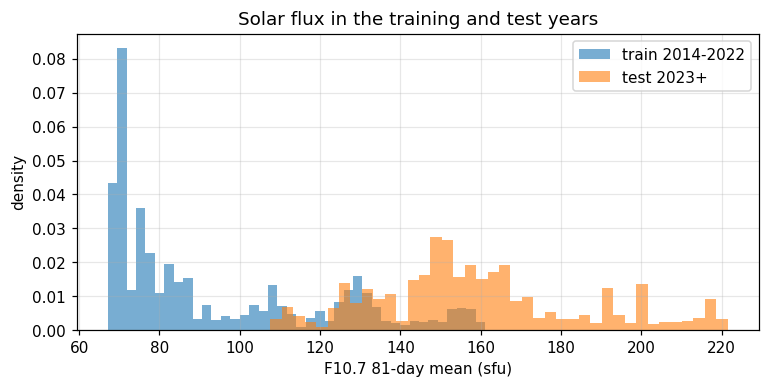

In [6]:
TRAIN_END, TEST_START = 2022, 2023
train = p[p["year"] <= TRAIN_END].copy()
test  = p[p["year"] >= TEST_START].copy()
X_train, y_train, X_test, y_test = train[FEATURES], train[TARGET], test[FEATURES], test[TARGET]
groups = train["year"]

summary = pd.DataFrame({
    "passes": [len(train), len(test)],
    "bubble passes": [y_train.sum(), y_test.sum()],
    "bubble rate %": [100 * y_train.mean(), 100 * y_test.mean()],
    "F10.7_81 max": [train["F107_81"].max(), test["F107_81"].max()],
}, index=["train 2014-2022", "test 2023+"]).round(1)
display(summary)
print(f"Test passes with F10.7_81 above the training maximum: {(test['F107_81'] > train['F107_81'].max()).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(train["F107_81"], bins=40, alpha=0.6, label="train 2014-2022", density=True)
ax.hist(test["F107_81"], bins=40, alpha=0.6, label="test 2023+", density=True)
ax.set_xlabel("F10.7 81-day mean (sfu)"); ax.set_ylabel("density"); ax.legend()
ax.set_title("Solar flux in the training and test years"); savefig("O2_F107_train_vs_test"); plt.show()

---
## Step 4: A common way to handle every model
We compare seven models. To treat them all the same way (train, predict, cross-validate), each one is wrapped so that it has a `.fit(data)` and a `.predict(data)` function. This cell only defines tools; nothing is trained yet.

In [7]:
def to_logit(q):
    q = np.clip(q, 1e-6, 1 - 1e-6); return np.log(q / (1 - q))

class SkModel:                       # wraps a scikit-learn / XGBoost classifier
    def __init__(self, make): self.make = make
    def fit(self, df): self.m = self.make().fit(df[FEATURES], df[TARGET]); return self
    def predict(self, df): return self.m.predict_proba(df[FEATURES])[:, 1]

class BaseRate:
    def fit(self, df): self.p0 = df[TARGET].mean(); return self
    def predict(self, df): return np.full(len(df), self.p0)

class Climatology:                   # rate per month x local-time hour, smoothed towards the overall rate
    def __init__(self, a=10): self.a = a
    def fit(self, df):
        self.p0 = df[TARGET].mean()
        t = df.groupby(["month", "LT_bin"])[TARGET].agg(k="sum", n="size")
        self.table = (t["k"] + self.a * self.p0) / (t["n"] + self.a); return self
    def predict(self, df):
        return self.table.reindex(pd.MultiIndex.from_arrays([df["month"], df["LT_bin"]])).fillna(self.p0).values

def run_cv(make_model, df, n_splits=5):
    # out-of-fold predictions with whole years held out (year-blocked cross-validation)
    oof = np.zeros(len(df))
    for tr_idx, va_idx in GroupKFold(n_splits).split(df, groups=df["year"]):
        oof[va_idx] = make_model().fit(df.iloc[tr_idx]).predict(df.iloc[va_idx])
    return oof
print("Tools defined.")

Tools defined.


---
## Step 5: The models
### 5a. Baselines (what every model has to beat)
1. **Base rate:** the same probability for every pass (the training-set bubble rate).
2. **Climatology:** the training-period rate for the same **month and local-time hour**. This is what an expert would read off a table.
3. **Logistic regression** with the 16 features, each entering as a straight line in log-odds. Missing values are filled with the training median and features are standardised, using training data only.

In [8]:
make_logit = lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=5000))
MODELS = {"Base rate": BaseRate, "Climatology": Climatology, "Logistic regression": lambda: SkModel(make_logit)}

### 5b. Random forest
500 decision trees, each grown on a random sample of the training passes. The probability is the average vote of the trees. `min_samples_leaf=20` stops trees from memorising single passes.

In [9]:
make_rf = lambda: make_pipeline(SimpleImputer(strategy="median"),
                                RandomForestClassifier(n_estimators=500, min_samples_leaf=20, max_features="sqrt",
                                                       n_jobs=-1, random_state=RANDOM_STATE))
MODELS["Random forest"] = lambda: SkModel(make_rf)

### 5c. XGBoost, with tuning
**Hyperparameters** are settings chosen *before* training:

| Setting | Meaning | Too high → | Too low → |
|---|---|---|---|
| `n_estimators` | number of trees | overfitting, slow | underfitting |
| `max_depth` | questions per tree (depth 3 = 3-way interactions) | memorises noise | misses interactions |
| `learning_rate` | how much each tree may correct | unstable | needs many trees |
| `subsample`, `colsample_bytree` | share of passes / features each tree sees | – | adds randomness that reduces overfitting |
| `min_child_weight` | minimum data in a leaf | too simple | memorises rare passes |
| `reg_alpha`, `reg_lambda` | penalties on large tree outputs (like lasso and ridge) | too simple | overfitting |

**Tuning without touching the test set: year-blocked cross-validation.**
1. Split the 9 training years into 5 groups of whole years.
2. Train on 4 groups and score on the 5th, rotating through all 5.
3. Try 40 random setting combinations and keep the best.

The score is **log-loss**, which rewards honest probabilities.

**Class imbalance:** we deliberately **don't** use `scale_pos_weight`. It inflates every probability, so a predicted 30% would no longer mean "30% of such passes have bubbles". Rarity is handled later, when choosing a warning threshold.

This takes 2–5 minutes.

In [10]:
param_dist = {
    "n_estimators":     [100, 200, 300, 500, 800],
    "max_depth":        [2, 3, 4, 5],
    "learning_rate":    [0.01, 0.02, 0.05, 0.1],
    "subsample":        [0.5, 0.7, 0.9],
    "colsample_bytree": [0.5, 0.7, 0.9],
    "min_child_weight": [1, 5, 10, 20],
    "reg_alpha":        [0, 0.1, 1],
    "reg_lambda":       [1, 5, 10],
}
xgb_base = xgb.XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist",
                             random_state=RANDOM_STATE, n_jobs=-1)
search = RandomizedSearchCV(xgb_base, param_dist, n_iter=40, scoring="neg_log_loss",
                            cv=GroupKFold(n_splits=5), random_state=RANDOM_STATE, n_jobs=1, verbose=1)
search.fit(X_train, y_train, groups=groups)
best_params = search.best_params_
print("Best settings:", best_params)
print(f"Cross-validated log-loss: {-search.best_score_:.4f}")
make_xgb = lambda: xgb.XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist",
                                     random_state=RANDOM_STATE, n_jobs=-1, **best_params)
MODELS["XGBoost"] = lambda: SkModel(make_xgb)

cvres = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
cvres["CV log-loss"] = -cvres["mean_test_score"]
cols = ["CV log-loss", "param_max_depth", "param_n_estimators", "param_learning_rate", "param_min_child_weight"]
print("Best 5 and worst 5 settings tried:"); display(pd.concat([cvres[cols].head(5), cvres[cols].tail(5)]).round(4))

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best settings: {'subsample': 0.5, 'reg_lambda': 1, 'reg_alpha': 0, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 2, 'learning_rate': 0.01, 'colsample_bytree': 0.5}
Cross-validated log-loss: 0.1533
Best 5 and worst 5 settings tried:


,CV log-loss,param_max_depth,param_n_estimators,param_learning_rate,param_min_child_weight
34,0.1533,2,300,0.01,5
6,0.1534,2,300,0.02,20
2,0.1534,3,200,0.01,10
24,0.1536,4,100,0.02,20
36,0.1536,3,200,0.02,10
15,0.1726,5,500,0.10,5
12,0.1727,4,800,0.05,10
33,0.1734,5,200,0.10,5
18,0.1997,5,800,0.05,1
9,0.2577,5,800,0.10,1


### 5d. Physics-informed logistic model (GLM)
This is a logistic regression whose *shape* follows what Objective 1 showed:
- **Local time** enters as a smooth spline curve, not a straight line, so it can rise after sunset, peak near 21 LT and fall after midnight.
- **Season** has **annual + semi-annual** terms, so it can have two equinox peaks.
- **Solar flux × local time** interaction: high F10.7 matters most in the evening, when the pre-reversal enhancement (PRE) acts.
- Storm and solar-wind drivers enter as straight lines.

Because it is a formula rather than a set of trees, it **keeps responding to solar flux beyond the values seen in training**. That matters here, because 40% of test passes have higher F10.7 than any training pass.

In [11]:
GLM_FORMULA = ("bubble ~ bs(LT_from18, df=5, lower_bound=0, upper_bound=12)"
               " + doy_sin + doy_cos + doy_sin2 + doy_cos2"
               " + F107_81 + F107 + Kp + Dst_min24 + AE_max6h + Bz_mean3h + alt_km"
               " + F107_81:LT_sin + F107_81:LT_cos")
GLM_COLS = ["LT_from18", "doy_sin", "doy_cos", "doy_sin2", "doy_cos2", "LT_sin", "LT_cos",
            "F107_81", "F107", "Kp", "Dst_min24", "AE_max6h", "Bz_mean3h", "alt_km"]

class PhysicsGLM:
    def fit(self, df):
        self.med = df[GLM_COLS].median()
        d = df.copy(); d[GLM_COLS] = d[GLM_COLS].fillna(self.med)
        self.res = smf.glm(GLM_FORMULA, d, family=sm.families.Binomial()).fit(); return self
    def predict(self, df):
        d = df.copy(); d[GLM_COLS] = d[GLM_COLS].fillna(self.med)
        return np.asarray(self.res.predict(d))

MODELS["Physics GLM"] = PhysicsGLM
glm_full = PhysicsGLM().fit(train)
print(glm_full.res.summary().tables[1])

                                                            coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------
Intercept                                                -5.6453      1.202     -4.696      0.000      -8.002      -3.289
bs(LT_from18, df=5, lower_bound=0, upper_bound=12)[0]     0.5878      0.748      0.786      0.432      -0.878       2.054
bs(LT_from18, df=5, lower_bound=0, upper_bound=12)[1]     1.6835      0.933      1.804      0.071      -0.145       3.512
bs(LT_from18, df=5, lower_bound=0, upper_bound=12)[2]     1.8968      1.123      1.688      0.091      -0.305       4.099
bs(LT_from18, df=5, lower_bound=0, upper_bound=12)[3]     1.7791      0.890      1.999      0.046       0.034       3.524
bs(LT_from18, df=5, lower_bound=0, upper_bound=12)[4]     2.3853      0.852      2.801      0.005       0.716       4.055
doy_sin                 

### 5e. Hybrid: physics GLM + XGBoost corrections
XGBoost **starts from the GLM's prediction**. It is passed as a starting value, called `base_margin`, so the trees only learn the *corrections* the GLM misses, such as interactions between storm drivers. This combines the GLM's ability to extrapolate in solar flux with the flexibility of trees.

The number of correction trees is chosen by year-blocked cross-validation on the training years. A choice of 0 means the trees add nothing.

In [12]:
HYB_PARAMS = dict(objective="binary:logistic", max_depth=2, eta=0.02, subsample=0.7,
                  colsample_bytree=0.7, min_child_weight=10, eval_metric="logloss", seed=RANDOM_STATE)

class HybridGLMXGB:
    def __init__(self, rounds=50): self.rounds = rounds
    def fit(self, df):
        self.glm = PhysicsGLM().fit(df)
        self.bst = None
        if self.rounds > 0:
            d = xgb.DMatrix(df[FEATURES], label=df[TARGET], base_margin=to_logit(self.glm.predict(df)))
            self.bst = xgb.train(HYB_PARAMS, d, num_boost_round=self.rounds)
        return self
    def predict(self, df):
        g = self.glm.predict(df)
        if self.bst is None:
            return g
        return self.bst.predict(xgb.DMatrix(df[FEATURES], base_margin=to_logit(g)))

hyb_cv = {}
for r in [0, 25, 50, 100, 200, 400]:
    hyb_cv[r] = log_loss(y_train, np.clip(run_cv(lambda: HybridGLMXGB(r), train), 1e-6, 1 - 1e-6))
display(pd.Series(hyb_cv, name="CV log-loss").round(5).to_frame().T)
BEST_ROUNDS = min(hyb_cv, key=hyb_cv.get)
print("Correction trees chosen by cross-validation:", BEST_ROUNDS)
MODELS["Hybrid GLM + XGBoost"] = lambda: HybridGLMXGB(BEST_ROUNDS)

,0,25,50,100,200,400
CV log-loss,0.15995,0.15976,0.16004,0.1602,0.16044,0.16159


Correction trees chosen by cross-validation: 25


### 5f. Compare all models by cross-validation on the training years
Still without touching the test years, we compare all seven models by year-blocked cross-validation. These out-of-fold predictions are reused in Step 7 to choose warning thresholds.

In [13]:
oof = {name: run_cv(make, train) for name, make in MODELS.items()}
cv_table = pd.DataFrame({m: {"CV ROC-AUC": roc_auc_score(y_train, v), "CV PR-AUC": average_precision_score(y_train, v),
                             "CV Brier": brier_score_loss(y_train, v), "CV log-loss": log_loss(y_train, np.clip(v, 1e-6, 1 - 1e-6))}
                         for m, v in oof.items()}).T
display(cv_table.round(4)); cv_table.to_csv(OUT_DIR / "O2_cv_training_scores.csv")

# final fit of every model on all training years, then predict the test years
fitted = {name: make().fit(train) for name, make in MODELS.items()}
pred = {name: m.predict(test) for name, m in fitted.items()}
xgb_model = fitted["XGBoost"].m

,CV ROC-AUC,CV PR-AUC,CV Brier,CV log-loss
Base rate,0.4338,0.0344,0.0376,0.1658
Climatology,0.5496,0.0535,0.0384,0.1770
Logistic regression,0.6978,0.0824,0.0375,0.1575
Random forest,0.7192,0.0952,0.0367,0.1546
XGBoost,0.7201,0.0944,0.0366,0.1535
Physics GLM,0.6897,0.0832,0.0379,0.1600
Hybrid GLM + XGBoost,0.6964,0.0850,0.0380,0.1598


---
## Step 6: Evaluate every model on the test years (2023+)

| Score | What it measures | Good value |
|---|---|---|
| **ROC-AUC** | Ranking: pick one bubble pass and one quiet pass at random. How often does the model give the bubble pass the higher probability? | 0.5 = guessing, 1 = perfect |
| **PR-AUC** (average precision) | Precision and recall averaged over all thresholds. Made for rare events | base rate = guessing, 1 = perfect |
| **Brier score** | Mean of (probability − outcome)², the mean squared error of probabilities | lower is better |
| **BSS vs climatology** | 1 − Brier(model) / Brier(climatology) | > 0 means it beats climatology |
| **Log-loss** | Average −log(probability given to what happened) | lower is better |

The **BSS against climatology** is the main O2 score. It answers whether the model knows more than a month × local-time table.

In [14]:
def scores(y, pr, p_clim):
    return {"ROC-AUC": roc_auc_score(y, pr), "PR-AUC": average_precision_score(y, pr),
            "Brier": brier_score_loss(y, pr),
            "BSS vs clim.": 1 - brier_score_loss(y, pr) / brier_score_loss(y, p_clim),
            "Log-loss": log_loss(y, np.clip(pr, 1e-6, 1 - 1e-6)),
            "Mean predicted %": 100 * np.mean(pr)}

table = pd.DataFrame({m: scores(y_test, pr, pred["Climatology"]) for m, pr in pred.items()}).T
table.to_csv(OUT_DIR / "O2_test_scores.csv")
display(table.round(3))
print(f"Observed bubble rate in the test years: {100 * y_test.mean():.1f}%  (PR-AUC of random guessing = {y_test.mean():.3f})")

,ROC-AUC,PR-AUC,Brier,BSS vs clim.,Log-loss,Mean predicted %
Base rate,0.500,0.115,0.107,-0.006,0.407,3.905
Climatology,0.571,0.164,0.107,0.000,0.444,3.643
Logistic regression,0.668,0.199,0.099,0.068,0.342,11.310
Random forest,0.679,0.202,0.099,0.073,0.342,8.121
XGBoost,0.663,0.181,0.101,0.050,0.355,6.752
Physics GLM,0.748,0.239,0.097,0.088,0.324,10.941
Hybrid GLM + XGBoost,0.748,0.240,0.097,0.090,0.324,11.101


Observed bubble rate in the test years: 11.5%  (PR-AUC of random guessing = 0.115)


**Reading the table.**
- *Mean predicted %* versus the observed test rate shows whether a model expected roughly the right number of bubbles. A model trained on lower-activity years will tend to **under-predict** at solar maximum.
- PR-AUC should be compared with the random-guessing value printed under the table, not with 0.5.
- **Compare with the cross-validation table in Step 5f.** Inside the training years, where solar flux is similar from fold to fold, XGBoost usually scores best. In the test years, which need predictions beyond the training flux range, the ranking can flip. Cross-validation within one solar-activity regime does **not** reveal a model's weakness at extrapolating, and that is a useful methodological point for the paper.

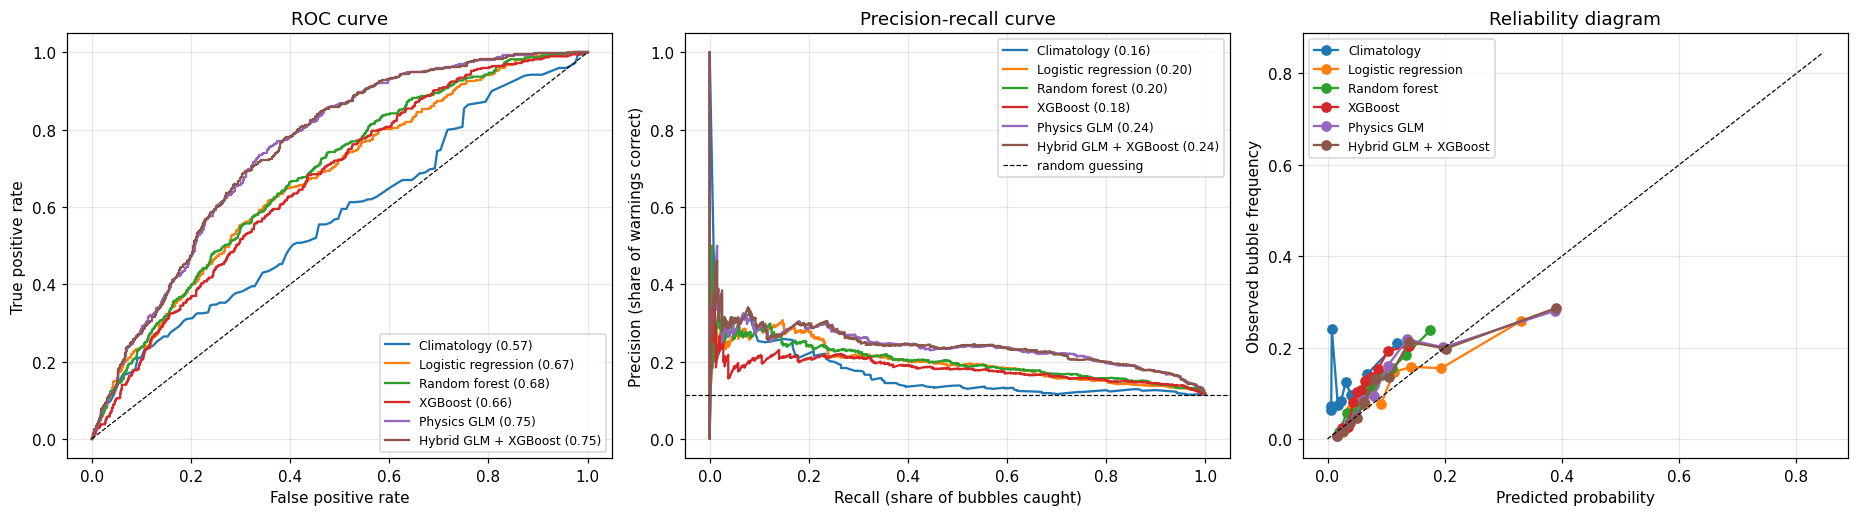

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for m, pr in pred.items():
    if m == "Base rate":
        continue
    fpr, tpr, _ = roc_curve(y_test, pr)
    axes[0].plot(fpr, tpr, label=f"{m} ({roc_auc_score(y_test, pr):.2f})")
    prec, rec, _ = precision_recall_curve(y_test, pr)
    axes[1].plot(rec, prec, label=f"{m} ({average_precision_score(y_test, pr):.2f})")
    frac, mean_pr = calibration_curve(y_test, pr, n_bins=10, strategy="quantile")
    axes[2].plot(mean_pr, frac, marker="o", label=m)
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8); axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=0.8, label="random guessing")
axes[1].set(xlabel="Recall (share of bubbles caught)", ylabel="Precision (share of warnings correct)", title="Precision-recall curve")
lim = max(0.6, max(np.max(v) for v in pred.values()))
axes[2].plot([0, lim], [0, lim], "k--", lw=0.8); axes[2].set(xlabel="Predicted probability", ylabel="Observed bubble frequency", title="Reliability diagram")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); savefig("O2_roc_pr_reliability"); plt.show()

**The reliability diagram** is the most important picture for a probability model. Points **above** the diagonal mean the model **under-predicts**: it says 10%, but bubbles happen 20% of the time. Points below mean it over-predicts.

---
## Step 7: From probabilities to yes/no warnings
A user may want a simple "warning" or "no warning". We need a **threshold**: warn if the probability is above *t*. Because bubbles are rare, *t* = 0.5 would almost never warn.

**Choose the threshold on the training years only:**
1. Make **out-of-fold** predictions for the training years. Each year is predicted by a model trained on the other years, so these predictions are honest.
2. Pick the threshold that maximises the **True Skill Statistic (TSS)**:
   - TSS = POD − POFD
   - POD (probability of detection) = share of bubble passes that were warned
   - POFD (probability of false detection) = share of quiet passes that were warned
   - TSS is widely used in space-weather forecasting because it is not fooled by rare events.
3. Apply that threshold **unchanged** to the test years.

Other scores reported:
- **FAR** (false alarm ratio) = share of warnings that were wrong
- **HSS** (Heidke skill score) = improvement over random chance

Thresholds chosen on training years (max TSS): {'Climatology': np.float64(0.07), 'Logistic regression': np.float64(0.02), 'Random forest': np.float64(0.03), 'XGBoost': np.float64(0.03), 'Physics GLM': np.float64(0.03), 'Hybrid GLM + XGBoost': np.float64(0.03)}


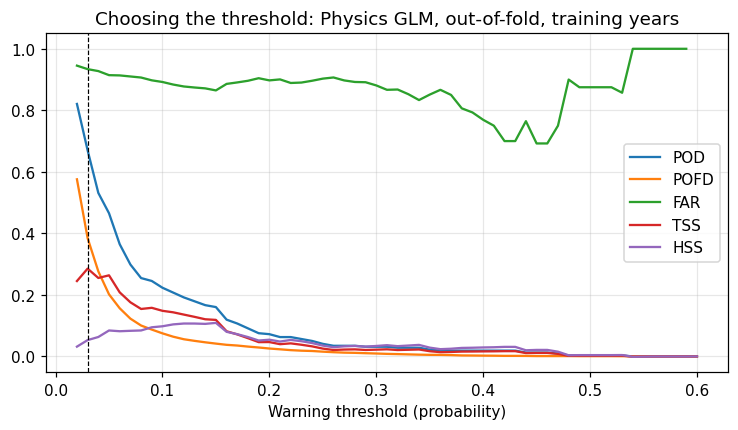

,threshold,TP,FP,FN,TN,POD,POFD,FAR,TSS,HSS
Climatology,0.07,94,359,306,2731,0.235,0.116,0.792,0.119,0.112
Logistic regression,0.02,400,3053,0,37,1.000,0.988,0.884,0.012,0.003
Random forest,0.03,393,2671,7,419,0.982,0.864,0.872,0.118,0.030
XGBoost,0.03,393,2804,7,286,0.982,0.907,0.877,0.075,0.019
Physics GLM,0.03,392,2452,8,638,0.980,0.794,0.862,0.186,0.051
Hybrid GLM + XGBoost,0.03,393,2450,7,640,0.982,0.793,0.862,0.190,0.052


,model,threshold,POD,FAR,TSS,HSS
0,Physics GLM,0.05,0.932,0.832,0.333,0.111
1,Physics GLM,0.10,0.698,0.778,0.381,0.197
2,Physics GLM,0.15,0.442,0.769,0.252,0.180
3,Physics GLM,0.20,0.320,0.746,0.198,0.178
4,Physics GLM,0.30,0.180,0.699,0.126,0.153
5,Hybrid GLM + XGBoost,0.05,0.935,0.834,0.329,0.109
6,Hybrid GLM + XGBoost,0.10,0.702,0.781,0.378,0.192
7,Hybrid GLM + XGBoost,0.15,0.460,0.766,0.265,0.187
8,Hybrid GLM + XGBoost,0.20,0.320,0.756,0.192,0.169
9,Hybrid GLM + XGBoost,0.30,0.178,0.703,0.123,0.149


In [16]:
def contingency(y, pr, t):
    yhat = (pr >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    pod = tp / (tp + fn) if tp + fn else np.nan
    pofd = fp / (fp + tn) if fp + tn else np.nan
    far = fp / (tp + fp) if tp + fp else np.nan
    n = tp + fp + fn + tn
    exp = ((tp + fn) * (tp + fp) + (tn + fn) * (tn + fp)) / n
    hss = (tp + tn - exp) / (n - exp) if n != exp else np.nan
    return {"threshold": t, "TP": tp, "FP": fp, "FN": fn, "TN": tn, "POD": pod, "POFD": pofd,
            "FAR": far, "TSS": pod - pofd, "HSS": hss}

ths = np.round(np.arange(0.02, 0.61, 0.01), 2)
thresholds = {}
for m in ["Climatology", "Logistic regression", "Random forest", "XGBoost", "Physics GLM", "Hybrid GLM + XGBoost"]:
    c = pd.DataFrame([contingency(y_train, oof[m], t) for t in ths])
    thresholds[m] = c.loc[c["TSS"].idxmax(), "threshold"]
    if m == "Physics GLM":
        curve = c
best_t = thresholds["Physics GLM"]
print("Thresholds chosen on training years (max TSS):", thresholds)

fig, ax = plt.subplots(figsize=(8, 4))
for c in ["POD", "POFD", "FAR", "TSS", "HSS"]:
    ax.plot(curve["threshold"], curve[c], label=c)
ax.axvline(best_t, color="k", ls="--", lw=0.8)
ax.set_xlabel("Warning threshold (probability)"); ax.set_title("Choosing the threshold: Physics GLM, out-of-fold, training years"); ax.legend()
savefig("O2_threshold_choice"); plt.show()

test_tables = pd.DataFrame([contingency(y_test, pred[m], t) for m, t in thresholds.items()], index=list(thresholds))
test_tables.to_csv(OUT_DIR / "O2_warning_scores.csv")
display(test_tables.round(3))

# Same comparison at a few fixed thresholds, for the Physics GLM and XGBoost
fixed = pd.DataFrame([{**{"model": m}, **contingency(y_test, pred[m], t)} for m in ["Physics GLM", "Hybrid GLM + XGBoost", "XGBoost"]
                      for t in [0.05, 0.10, 0.15, 0.20, 0.30]])
display(fixed[["model", "threshold", "POD", "FAR", "TSS", "HSS"]].round(3))
fixed.to_csv(OUT_DIR / "O2_warning_scores_fixed_thresholds.csv", index=False)

**How to read this.** A threshold chosen in the training years (bubble rate about 4%) can be too low for solar-maximum years (rate about 11%), and then it warns almost every pass. The fixed-threshold table shows the trade-off directly. With a given threshold, POD says what share of the test-year bubble passes would have received a warning, and FAR says what share of the warnings were false alarms. A **lower** threshold catches more bubbles at the cost of more false alarms. The right balance depends on the user, for example GNSS surveying vs aviation.

---
## Step 8: Are the differences between models real? (bootstrap)
Every test score has sampling uncertainty. We **resample whole nights** from the test set 1,000 times with replacement, recompute the scores, and take the 2.5–97.5% range as a 95% confidence interval. We also bootstrap the **difference** between the Physics GLM and each other model. If its interval excludes 0, the difference is real.

In [17]:
rng = np.random.default_rng(1)
nights = test["night_id"].values
uniq, inv = np.unique(nights, return_inverse=True)
rows_of = [np.where(inv == i)[0] for i in range(len(uniq))]
yv = y_test.values
models = ["Climatology", "Logistic regression", "Random forest", "XGBoost", "Physics GLM", "Hybrid GLM + XGBoost"]
boot = {m: {"ROC-AUC": [], "BSS vs clim.": []} for m in models}
REF = "Physics GLM"
diff = {m: {"ROC-AUC": [], "Brier": []} for m in models if m != REF}
for _ in range(1000):
    pick = np.concatenate([rows_of[i] for i in rng.integers(0, len(uniq), len(uniq))])
    yb = yv[pick]
    if yb.min() == yb.max():
        continue
    bc = brier_score_loss(yb, pred["Climatology"][pick])
    s = {}
    for m in models:
        pb = pred[m][pick]
        s[m] = (roc_auc_score(yb, pb), brier_score_loss(yb, pb))
        boot[m]["ROC-AUC"].append(s[m][0]); boot[m]["BSS vs clim."].append(1 - s[m][1] / bc)
    for m in diff:
        diff[m]["ROC-AUC"].append(s[REF][0] - s[m][0]); diff[m]["Brier"].append(s[REF][1] - s[m][1])

ci = pd.DataFrame({m: {k: f"{table.loc[m, k]:.3f} ({np.percentile(v, 2.5):.3f} to {np.percentile(v, 97.5):.3f})"
                       for k, v in boot[m].items()} for m in models}).T
display(ci)
dt = pd.DataFrame({f"{REF} minus {m}": {k: f"{np.mean(v):+.4f} ({np.percentile(v, 2.5):+.4f} to {np.percentile(v, 97.5):+.4f})"
                                            for k, v in d.items()} for m, d in diff.items()}).T
display(dt)
ci.to_csv(OUT_DIR / "O2_bootstrap_ci.csv"); dt.to_csv(OUT_DIR / "O2_bootstrap_differences.csv")
print(f"For ROC-AUC a positive difference favours the {REF}; for Brier a NEGATIVE difference favours the {REF}.")

,ROC-AUC,BSS vs clim.
Climatology,0.571 (0.535 to 0.607),0.000 (0.000 to 0.000)
Logistic regression,0.668 (0.638 to 0.701),0.068 (0.034 to 0.097)
Random forest,0.679 (0.649 to 0.711),0.073 (0.057 to 0.086)
XGBoost,0.663 (0.631 to 0.695),0.050 (0.038 to 0.061)
Physics GLM,0.748 (0.721 to 0.775),0.088 (0.046 to 0.125)
Hybrid GLM + XGBoost,0.748 (0.721 to 0.775),0.090 (0.048 to 0.127)


,ROC-AUC,Brier
Physics GLM minus Climatology,+0.1769 (+0.1363 to +0.2166),-0.0093 (-0.0141 to -0.0046)
Physics GLM minus Logistic regression,+0.0807 (+0.0578 to +0.1025),-0.0021 (-0.0048 to +0.0005)
Physics GLM minus Random forest,+0.0691 (+0.0432 to +0.0936),-0.0016 (-0.0052 to +0.0022)
Physics GLM minus XGBoost,+0.0861 (+0.0603 to +0.1123),-0.0040 (-0.0078 to -0.0001)
Physics GLM minus Hybrid GLM + XGBoost,+0.0001 (-0.0022 to +0.0023),+0.0002 (+0.0000 to +0.0005)


For ROC-AUC a positive difference favours the Physics GLM; for Brier a NEGATIVE difference favours the Physics GLM.


---
## Step 9: Where does the model work, and where does it fail?
Scores inside sub-groups of the test set: each test year, local time, season and solar-flux level. Groups with very few bubbles give unstable scores, so the number of bubble passes is shown.

In [18]:
test = test.assign(p_xgb=pred["XGBoost"], p_log=pred["Logistic regression"], p_clim=pred["Climatology"],
                   p_glm=pred["Physics GLM"], p_hyb=pred["Hybrid GLM + XGBoost"])
test["F107_lvl"] = pd.cut(test["F107_81"], [0, 130, 150, 170, 250], labels=["<130", "130-150", "150-170", ">170"])
test["LT_grp"] = pd.cut(test["LT_from18"], [0, 2, 4, 6, 12], right=False, labels=["18-20", "20-22", "22-24", "00-06"])

def group_scores(by):
    rows = []
    for key, g in test.groupby(by, observed=True):
        if g[TARGET].nunique() < 2:
            continue
        bc = brier_score_loss(g[TARGET], g["p_clim"])
        rows.append({by: key, "passes": len(g), "bubbles": int(g[TARGET].sum()),
                     "observed %": 100 * g[TARGET].mean(), "XGB mean pred %": 100 * g["p_xgb"].mean(),
                     "GLM mean pred %": 100 * g["p_glm"].mean(),
                     "XGB ROC-AUC": roc_auc_score(g[TARGET], g["p_xgb"]),
                     "XGB BSS": 1 - brier_score_loss(g[TARGET], g["p_xgb"]) / bc,
                     "GLM ROC-AUC": roc_auc_score(g[TARGET], g["p_glm"]),
                     "GLM BSS": 1 - brier_score_loss(g[TARGET], g["p_glm"]) / bc,
                     "Hybrid BSS": 1 - brier_score_loss(g[TARGET], g["p_hyb"]) / bc})
    return pd.DataFrame(rows).round(3)

for by in ["year", "LT_grp", "season", "F107_lvl"]:
    t = group_scores(by); display(t); t.to_csv(OUT_DIR / f"O2_scores_by_{by}.csv", index=False)

,year,passes,bubbles,observed %,XGB mean pred %,GLM mean pred %,XGB ROC-AUC,XGB BSS,GLM ROC-AUC,GLM BSS,Hybrid BSS
0,2023,905,100,11.050,6.634,9.163,0.658,0.055,0.732,0.084,0.084
1,2024,909,147,16.172,6.407,14.949,0.662,0.073,0.779,0.157,0.162
2,2025,916,113,12.336,7.752,12.221,0.663,0.022,0.686,0.032,0.035
3,2026,760,40,5.263,6.099,6.722,0.679,0.035,0.656,-0.006,-0.011


,LT_grp,passes,bubbles,observed %,XGB mean pred %,GLM mean pred %,XGB ROC-AUC,XGB BSS,GLM ROC-AUC,GLM BSS,Hybrid BSS
0,18-20,548,45,8.212,7.655,16.649,0.634,0.029,0.676,-0.189,-0.185
1,20-22,580,149,25.690,8.151,17.993,0.509,0.063,0.616,0.166,0.169
2,22-24,613,111,18.108,7.628,13.528,0.522,0.033,0.646,0.088,0.089
3,00-06,1749,95,5.432,5.698,5.907,0.783,0.061,0.780,0.097,0.097


,season,passes,bubbles,observed %,XGB mean pred %,GLM mean pred %,XGB ROC-AUC,XGB BSS,GLM ROC-AUC,GLM BSS,Hybrid BSS
0,Dec sol.,1054,111,10.531,7.664,11.847,0.657,0.047,0.698,0.053,0.052
1,Jun sol.,1235,71,5.749,4.973,7.085,0.665,0.045,0.788,0.083,0.083
2,Mar eq.,593,115,19.393,8.005,12.832,0.533,0.054,0.651,0.113,0.118
3,Sep eq.,608,103,16.941,7.562,15.359,0.645,0.054,0.738,0.101,0.107


,F107_lvl,passes,bubbles,observed %,XGB mean pred %,GLM mean pred %,XGB ROC-AUC,XGB BSS,GLM ROC-AUC,GLM BSS,Hybrid BSS
0,<130,432,16,3.704,4.866,5.765,0.625,0.017,0.704,-0.002,-0.010
1,130-150,898,77,8.575,7.092,8.197,0.684,0.035,0.693,0.020,0.017
2,150-170,1223,141,11.529,6.994,10.167,0.646,0.037,0.716,0.068,0.072
3,>170,899,161,17.909,6.806,17.423,0.653,0.074,0.739,0.150,0.155


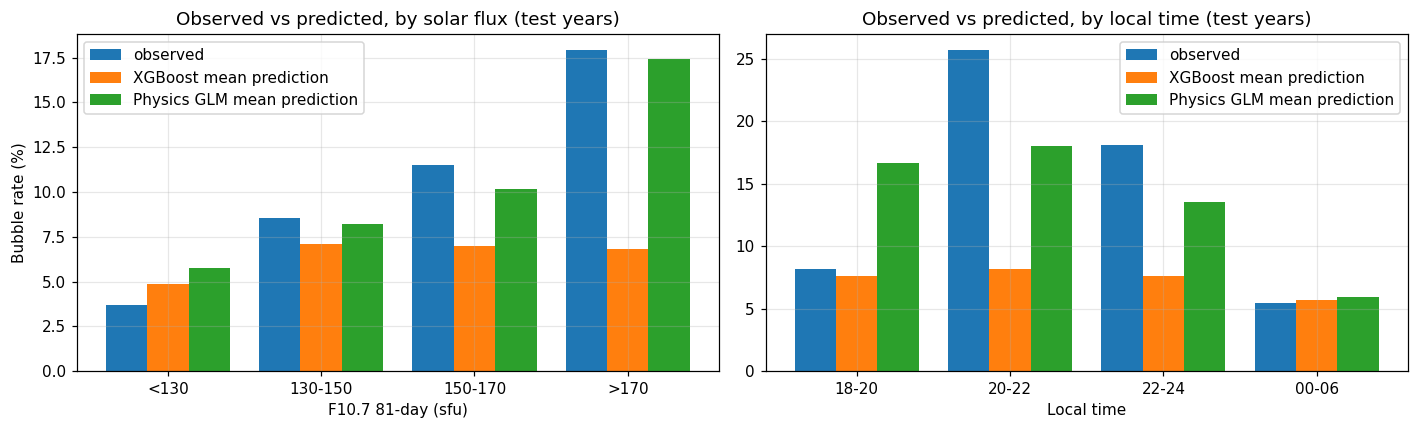

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
t = group_scores("F107_lvl")
x = np.arange(len(t))
axes[0].bar(x - 0.27, t["observed %"], 0.27, label="observed")
axes[0].bar(x, t["XGB mean pred %"], 0.27, label="XGBoost mean prediction")
axes[0].bar(x + 0.27, t["GLM mean pred %"], 0.27, label="Physics GLM mean prediction")
axes[0].set_xticks(x); axes[0].set_xticklabels(t["F107_lvl"]); axes[0].set_xlabel("F10.7 81-day (sfu)")
axes[0].set_ylabel("Bubble rate (%)"); axes[0].legend(); axes[0].set_title("Observed vs predicted, by solar flux (test years)")
t = group_scores("LT_grp"); x = np.arange(len(t))
axes[1].bar(x - 0.27, t["observed %"], 0.27, label="observed")
axes[1].bar(x, t["XGB mean pred %"], 0.27, label="XGBoost mean prediction")
axes[1].bar(x + 0.27, t["GLM mean pred %"], 0.27, label="Physics GLM mean prediction")
axes[1].set_xticks(x); axes[1].set_xticklabels(t["LT_grp"]); axes[1].set_xlabel("Local time")
axes[1].legend(); axes[1].set_title("Observed vs predicted, by local time (test years)")
plt.tight_layout(); savefig("O2_observed_vs_predicted"); plt.show()

---
## Step 10: Cycle 24 → Cycle 25 transfer test (second half of O2)
*Does a model trained only on Solar Cycle 24 still work at the Cycle 25 maximum?*

Three training periods, all tested on the same 2023+ passes:

| Model | Trained on | Highest F10.7_81 seen in training |
|---|---|---|
| C24 only | 2014–2019 | about 160 sfu |
| C24 + C25 rise | 2014–2022 (main split) | about 160 sfu |
| Reference: leave-one-year-out | all other years, including other Cycle 25 maximum years | up to about 220 sfu |

**Why tree models can struggle here.** A decision tree can only say "F10.7 above 155 → high risk". It has no rule for 200 sfu if it never saw 200 sfu, so its predictions **flatten** beyond the training range. Logistic regression extends its straight line (in log-odds), so it *can* extrapolate, though not necessarily correctly. Comparing the two shows whether the drop at solar maximum comes from **extrapolation** or from a **real change** in bubble behaviour.

The reference row predicts each test year with a model trained on all other years. That is the best we could expect with Cycle 25 maximum data available.

In [20]:
TRANSFER_MODELS = ["Climatology", "Logistic regression", "XGBoost", "Physics GLM", "Hybrid GLM + XGBoost"]
transfer_pred = {}
for name, last_year in [("C24 only (2014-19)", 2019), ("C24 + C25 rise (2014-22)", 2022)]:
    tr = p[p["year"] <= last_year]
    for m in TRANSFER_MODELS:
        transfer_pred[(name, m)] = MODELS[m]().fit(tr).predict(test)

# reference: each test year predicted by models trained on ALL other years (including other Cycle 25 maximum years)
for m in TRANSFER_MODELS:
    v = np.zeros(len(test))
    for yr in sorted(test["year"].unique()):
        mask = (test["year"] == yr).values
        v[mask] = MODELS[m]().fit(p[p["year"] != yr]).predict(test[mask])
    transfer_pred[("Reference: leave-one-year-out", m)] = v

rows = []
for (period, model), pr in transfer_pred.items():
    clim_ref = transfer_pred[(period, "Climatology")]
    rows.append({"trained on": period, "model": model,
                 "ROC-AUC": roc_auc_score(y_test, pr), "PR-AUC": average_precision_score(y_test, pr),
                 "Brier": brier_score_loss(y_test, pr),
                 "BSS vs same-period clim.": 1 - brier_score_loss(y_test, pr) / brier_score_loss(y_test, clim_ref),
                 "mean predicted %": 100 * pr.mean()})
transfer = pd.DataFrame(rows)
transfer.to_csv(OUT_DIR / "O2_cycle_transfer.csv", index=False)
display(transfer.round(3))
print(f"Observed bubble rate in test years: {100 * y_test.mean():.1f}%")

,trained on,model,ROC-AUC,PR-AUC,Brier,BSS vs same-period clim.,mean predicted %
0,C24 only (2014-19),Climatology,0.599,0.176,0.106,0.000,3.955
1,C24 only (2014-19),Logistic regression,0.658,0.190,0.101,0.045,10.669
2,C24 only (2014-19),XGBoost,0.652,0.177,0.102,0.036,6.479
3,C24 only (2014-19),Physics GLM,0.736,0.228,0.098,0.072,10.282
4,C24 only (2014-19),Hybrid GLM + XGBoost,0.737,0.230,0.098,0.074,10.259
5,C24 + C25 rise (2014-22),Climatology,0.571,0.164,0.107,0.000,3.643
6,C24 + C25 rise (2014-22),Logistic regression,0.668,0.199,0.099,0.068,11.310
7,C24 + C25 rise (2014-22),XGBoost,0.663,0.181,0.101,0.050,6.752
8,C24 + C25 rise (2014-22),Physics GLM,0.748,0.239,0.097,0.088,10.941
9,C24 + C25 rise (2014-22),Hybrid GLM + XGBoost,0.748,0.240,0.097,0.090,11.101


Observed bubble rate in test years: 11.5%


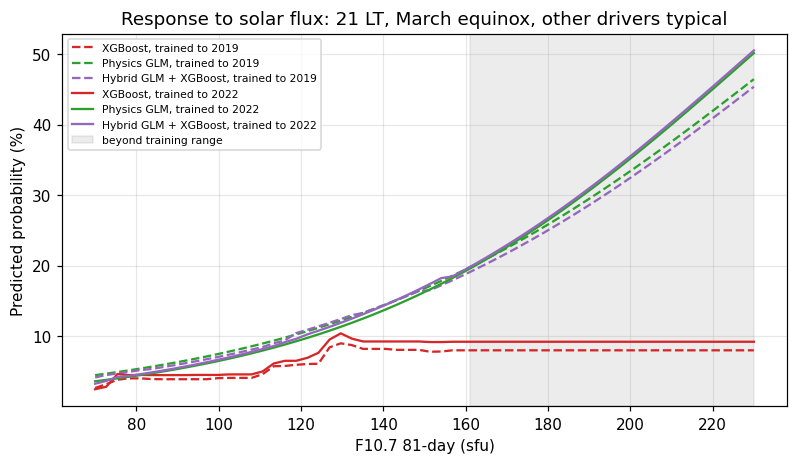

In [21]:
# How does each model respond to F10.7 beyond the training range? (21 LT, March equinox, other drivers typical)
cols = list(dict.fromkeys(GLM_COLS + FEATURES))
grid = pd.DataFrame([test[cols].median()] * 60).reset_index(drop=True)
grid["F107_81"] = np.linspace(70, 230, 60); grid["F107"] = grid["F107_81"]
grid["LT_from18"] = 3.0; grid["LT_sin"], grid["LT_cos"] = np.sin(2*np.pi*21/24), np.cos(2*np.pi*21/24)
d = 80; grid["doy_sin"], grid["doy_cos"] = np.sin(2*np.pi*d/365.25), np.cos(2*np.pi*d/365.25)
grid["doy_sin2"], grid["doy_cos2"] = np.sin(4*np.pi*d/365.25), np.cos(4*np.pi*d/365.25)
fig, ax = plt.subplots(figsize=(8.5, 4.4))
colors = {"XGBoost": "tab:red", "Physics GLM": "tab:green", "Hybrid GLM + XGBoost": "tab:purple"}
for last_year, ls in [(2019, "--"), (2022, "-")]:
    tr = p[p["year"] <= last_year]
    for m, c in colors.items():
        ax.plot(grid["F107_81"], 100 * MODELS[m]().fit(tr).predict(grid), ls=ls, color=c, label=f"{m}, trained to {last_year}")
ax.axvspan(train["F107_81"].max(), 230, color="grey", alpha=0.15, label="beyond training range")
ax.set_xlabel("F10.7 81-day (sfu)"); ax.set_ylabel("Predicted probability (%)")
ax.set_title("Response to solar flux: 21 LT, March equinox, other drivers typical"); ax.legend(fontsize=7)
savefig("O2_extrapolation_F107"); plt.show()

**How to read Step 10.**
- Compare the flat XGBoost curve in the grey zone with the GLM and hybrid curves, which keep rising.
- If XGBoost trained on 2014–2019 or 2014–2022 **under-predicts** (mean predicted % well below the observed rate) and its curve is **flat** in the grey zone, the cycle-transfer problem is mainly **extrapolation**: the model has never seen such high flux.
- If the leave-one-year-out reference scores much better, the model works once similar solar conditions are in the training data. That is an argument for **retraining as each new solar maximum arrives**, and it is a useful practical conclusion for the paper.

---
## Step 11: Why not a random split? (for the Methods section)
Here we train the same XGBoost on a **random 80/20 split of all passes**, the way many studies do. The difference from the time-based split shows how much near-duplicate passes (Swarm A/C, same night) and shared solar-cycle conditions inflate the scores.

In [22]:
Xa, Xb, ya, yb = train_test_split(p[FEATURES], p[TARGET], test_size=0.2, random_state=RANDOM_STATE, stratify=p[TARGET])
rnd = make_xgb().fit(Xa, ya).predict_proba(Xb)[:, 1]
cmp_split = pd.DataFrame({
    "Random 80/20 split": {"ROC-AUC": roc_auc_score(yb, rnd), "PR-AUC": average_precision_score(yb, rnd)},
    "Time split (train <=2022, test 2023+)": {"ROC-AUC": table.loc["XGBoost", "ROC-AUC"], "PR-AUC": table.loc["XGBoost", "PR-AUC"]},
}).T
display(cmp_split.round(3))

,ROC-AUC,PR-AUC
Random 80/20 split,0.832,0.269
"Time split (train <=2022, test 2023+)",0.663,0.181


---
## Step 12: Which features does XGBoost rely on? (quick look) and saving the model
**Permutation importance** is a quick check before the full SHAP analysis in Objective 3:
1. Shuffle one feature in the test set, which breaks its link with the outcome.
2. See how much the ROC-AUC drops.
A big drop means the model relies on that feature.

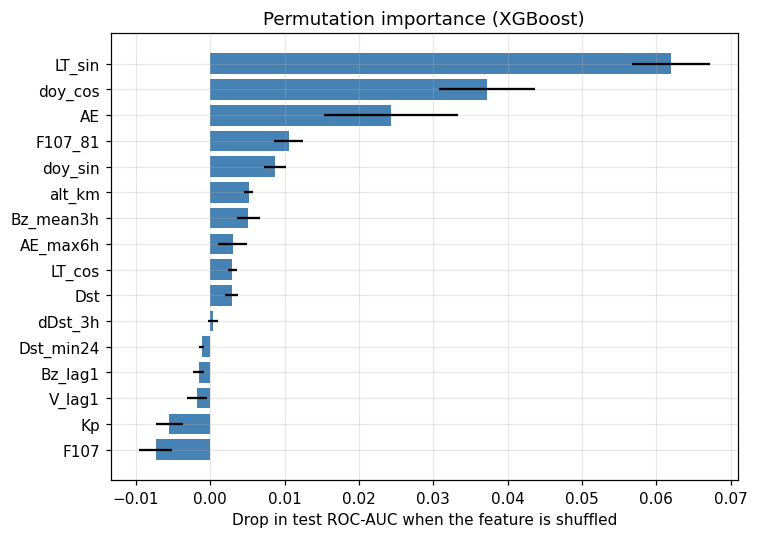

In [23]:
perm = permutation_importance(xgb_model, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"AUC drop": perm.importances_mean, "sd": perm.importances_std}, index=FEATURES).sort_values("AUC drop")
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index, imp["AUC drop"], xerr=imp["sd"], color="steelblue")
ax.set_xlabel("Drop in test ROC-AUC when the feature is shuffled"); ax.set_title("Permutation importance (XGBoost)")
plt.tight_layout(); savefig("O2_permutation_importance"); plt.show()
imp.sort_values("AUC drop", ascending=False).to_csv(OUT_DIR / "O2_permutation_importance.csv")

In [24]:
xgb_model.save_model(OUT_DIR / "xgb_model.json")
fitted["Physics GLM"].res.save(str(OUT_DIR / "physics_glm.pickle"))
if fitted["Hybrid GLM + XGBoost"].bst is not None:
    fitted["Hybrid GLM + XGBoost"].bst.save_model(OUT_DIR / "hybrid_xgb_corrections.json")
json.dump({"features": FEATURES, "best_params": best_params, "thresholds_TSS": {k: float(v) for k, v in thresholds.items()},
           "glm_formula": GLM_FORMULA, "hybrid_rounds": int(BEST_ROUNDS),
           "train_years": [int(train['year'].min()), TRAIN_END], "test_start": TEST_START},
          open(OUT_DIR / "model_info.json", "w"), indent=2)
out = test[["sat", "t_eq", "year", "LT", "month", "F107_81", "Kp", TARGET]].copy()
for m, pr in pred.items():
    out[f"p_{m.replace(' ', '_').lower()}"] = pr
out.to_csv(OUT_DIR / "O2_test_predictions.csv", index=False)
print("Saved model, settings and test predictions to", OUT_DIR)

Saved model, settings and test predictions to /content/drive/MyDrive/EPB_SriLanka/results/O2


---
## Summary (filled in from your data)

In [25]:
tr_x = transfer.set_index(["trained on", "model"])
def line(m):
    r = table.loc[m]
    return (f"{m}: ROC-AUC {r['ROC-AUC']:.3f}, PR-AUC {r['PR-AUC']:.3f}, BSS vs climatology {r['BSS vs clim.']:.3f}, "
            f"mean predicted {r['Mean predicted %']:.1f}%")
w = test_tables.loc["Physics GLM"]
lines = [
    f"Training 2014-{TRAIN_END}: {len(train):,} passes ({100*y_train.mean():.1f}% bubbles). Test {TEST_START}+: {len(test):,} passes "
    f"({100*y_test.mean():.1f}% bubbles; random-guess PR-AUC = {y_test.mean():.3f}).",
    *[line(m) for m in ["Climatology", "Logistic regression", "Random forest", "XGBoost", "Physics GLM", "Hybrid GLM + XGBoost"]],
    f"Physics GLM warnings (threshold {thresholds['Physics GLM']:.2f} from training years): POD {w['POD']:.2f}, FAR {w['FAR']:.2f}, TSS {w['TSS']:.2f}.",
    "Cycle transfer, ROC-AUC on 2023+ (trained 2014-19 / 2014-22 / leave-one-year-out): " + "; ".join(
        f"{m} {tr_x.loc[('C24 only (2014-19)', m), 'ROC-AUC']:.3f} / {tr_x.loc[('C24 + C25 rise (2014-22)', m), 'ROC-AUC']:.3f} / "
        f"{tr_x.loc[('Reference: leave-one-year-out', m), 'ROC-AUC']:.3f}" for m in ["XGBoost", "Physics GLM", "Hybrid GLM + XGBoost"]),
    f"Random split would report XGBoost ROC-AUC {cmp_split.iloc[0,0]:.3f} vs {cmp_split.iloc[1,0]:.3f} with the time split.",
    "Top XGBoost features (permutation): " + ", ".join(imp.sort_values('AUC drop', ascending=False).index[:5]) + ".",
]
s = "\n".join("- " + l for l in lines); print(s)
_ = (OUT_DIR / "O2_summary.txt").write_text(s)

- Training 2014-2022: 8,143 passes (3.9% bubbles). Test 2023+: 3,490 passes (11.5% bubbles; random-guess PR-AUC = 0.115).
- Climatology: ROC-AUC 0.571, PR-AUC 0.164, BSS vs climatology 0.000, mean predicted 3.6%
- Logistic regression: ROC-AUC 0.668, PR-AUC 0.199, BSS vs climatology 0.068, mean predicted 11.3%
- Random forest: ROC-AUC 0.679, PR-AUC 0.202, BSS vs climatology 0.073, mean predicted 8.1%
- XGBoost: ROC-AUC 0.663, PR-AUC 0.181, BSS vs climatology 0.050, mean predicted 6.8%
- Physics GLM: ROC-AUC 0.748, PR-AUC 0.239, BSS vs climatology 0.088, mean predicted 10.9%
- Hybrid GLM + XGBoost: ROC-AUC 0.748, PR-AUC 0.240, BSS vs climatology 0.090, mean predicted 11.1%
- Physics GLM warnings (threshold 0.03 from training years): POD 0.98, FAR 0.86, TSS 0.19.
- Cycle transfer, ROC-AUC on 2023+ (trained 2014-19 / 2014-22 / leave-one-year-out): XGBoost 0.652 / 0.663 / 0.754; Physics GLM 0.736 / 0.748 / 0.791; Hybrid GLM + XGBoost 0.737 / 0.748 / 0.791
- Random split would report XGBoost